In [5]:
import pandas as pd

In [1]:
from datasets import load_dataset

## Exploration

In [5]:
df = load_dataset("stanfordnlp/imdb")

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

In [7]:
print(df) # it is not normal python dictionary , huggingface datasets library has it own data structure , DatasetDict - collection of dataset objects

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})


In [9]:
df["train"][0] # each row example is represented like a dictionary, 0 - negative, 1 - positive

{'text': 'I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the sex and nudity scenes are few and far be

In [10]:
df["train"].features

{'text': Value('string'), 'label': ClassLabel(names=['neg', 'pos'])}

In [11]:
len(df["train"]) # 25,000 

25000

In [12]:
len(df["test"]) # 25,000

25000

In [13]:
len(df["unsupervised"]) # 50,000

50000

In [14]:
df["train"].column_names

['text', 'label']

In [15]:
df["unsupervised"].column_names

['text', 'label']

In [18]:
df["unsupervised"][0]

{'text': 'This is just a precious little diamond. The play, the script are excellent. I cant compare this movie with anything else, maybe except the movie "Leon" wonderfully played by Jean Reno and Natalie Portman. But... What can I say about this one? This is the best movie Anne Parillaud has ever played in (See please "Frankie Starlight", she\'s speaking English there) to see what I mean. The story of young punk girl Nikita, taken into the depraved world of the secret government forces has been exceptionally over used by Americans. Never mind the "Point of no return" and especially the "La femme Nikita" TV series. They cannot compare the original believe me! Trash these videos. Buy this one, do not rent it, BUY it. BTW beware of the subtitles of the LA company which "translate" the US release. What a disgrace! If you cant understand French, get a dubbed version. But you\'ll regret later :)',
 'label': -1}

In [19]:
# for exploration we convert it to pandas

train_df = df["train"].to_pandas()

In [20]:
train_df.head()

,text,label
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0
3,This film was probably inspired by Godard's Ma...,0
4,"Oh, brother...after hearing about this ridicul...",0


In [21]:
train_df.isnull().sum()

text     0
label    0
dtype: int64

In [22]:
validation = df["train"].train_test_split(test_size=0.2,seed=42)

In [23]:
validation

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 20000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 5000
    })
})

In [24]:
train_dataset = validation["train"]
val_dataset = validation["test"]

In [25]:
train_dataset

Dataset({
    features: ['text', 'label'],
    num_rows: 20000
})

In [26]:
val_dataset

Dataset({
    features: ['text', 'label'],
    num_rows: 5000
})

## Pre-Process

In [28]:
train_dataset[3]

{'text': 'Two years ago I watched "The Matador" in cinema and I loved everything about this movie. Obviously, I was totally under impression of Pierce Brosan\'s magnificent role. Yesterday, I caught this movie again on TV so I looked at it a bit deeper. Now, I can say with certain that this movie isn\'t that special but you just gotta\' love it because of one man. <br /><br />Brosnan lifts its grade up in my opinion with amazing performance of Julian Noble, tired hit-man who has no friends. Soon Julian meets Danny Wright (Greg Kinnear) in Mexico City, man who\'s got bad luck: his son died in accident, his job isn\'t going that well and he\'s not sure that he can keep his wife Bean (Hope Davis).<br /><br />I always liked movies like this; crime movie with big touch of humor. Mostly that humor comes from Brosnan as he tells jokes about dwarfs with big d.... or one of my favorite lines in this movie: "I look like a Bangkok hooker on a Sunday morning, after the navy\'s left town." Brosnan 

In [35]:
import re # regular expression module in python

def clean_data(text):
    text = re.sub(r"<.*?>"," ",text) # remove html tag
    text = re.sub(r"\s+"," ",text) # remove spaces

    return text



In [37]:
train_dataset = train_dataset.map(
    lambda x : {"text":
               clean_data(x["text"])}
)
val_dataset = val_dataset.map(
    lambda x : {"text":
               clean_data(x["text"])}
)

Map:   0%|          | 0/20000 [00:00<?, ? examples/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

In [39]:
train_dataset[3]

{'text': 'Two years ago I watched "The Matador" in cinema and I loved everything about this movie. Obviously, I was totally under impression of Pierce Brosan\'s magnificent role. Yesterday, I caught this movie again on TV so I looked at it a bit deeper. Now, I can say with certain that this movie isn\'t that special but you just gotta\' love it because of one man. Brosnan lifts its grade up in my opinion with amazing performance of Julian Noble, tired hit-man who has no friends. Soon Julian meets Danny Wright (Greg Kinnear) in Mexico City, man who\'s got bad luck: his son died in accident, his job isn\'t going that well and he\'s not sure that he can keep his wife Bean (Hope Davis). I always liked movies like this; crime movie with big touch of humor. Mostly that humor comes from Brosnan as he tells jokes about dwarfs with big d.... or one of my favorite lines in this movie: "I look like a Bangkok hooker on a Sunday morning, after the navy\'s left town." Brosnan says it with his charm 

## Tokenize

In [42]:
from transformers import AutoTokenizer , AutoModelForSequenceClassification

tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

In [43]:
def tokenize(data):
    return tokenizer(
        data["text"],
        padding="max_length",
        max_length=512,
        truncation=True
    )

In [44]:
train_dataset = train_dataset.map(tokenize)
val_dataset = val_dataset.map(tokenize)

Map:   0%|          | 0/20000 [00:00<?, ? examples/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

In [46]:
type(train_dataset[0])

dict

In [47]:
len(train_dataset[0]["input_ids"])

512

In [52]:
# original dataset call the target - label , but huggingface models conventionally expect the target - labels

train_dataset = train_dataset.rename_column("label","labels")
val_dataset = val_dataset.rename_column("label","labels")

In [53]:
train_dataset.column_names

['text', 'labels', 'input_ids', 'token_type_ids', 'attention_mask']

## Fine-tune the model

In [49]:
model = AutoModelForSequenceClassification.from_pretrained("distilbert-base-uncased",num_labels=2)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [54]:
# random sampling

train_small = train_dataset.shuffle(seed=42).select(range(4000))
val_small = val_dataset.shuffle(seed=42).select(range(500))

In [56]:
import torch

# on what device we want to train our model 

if torch.backends.mps.is_available():
    device = torch.device("mps") # for Mac
elif torch.cuda.is_available():
    device = torch.device("cuda") # for GPU
else :
    device = torch.device("cpu")

print("device: ",device)
model.to(device)

device:  mps


DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
          (ffn): FFN(
            (dropout): Dropout(

In [57]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir = "./results",

    num_train_epochs=3,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    learning_rate = 2e-5,
    warmup_steps=500,
    eval_strategy="epoch",
    save_strategy="epoch"
                               
)

In [58]:
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_small,
    eval_dataset=val_small
)

In [59]:
trainer.train()

/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss
1,0.442795,0.362282
2,0.258399,0.415331
3,0.117969,0.477361


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1500, training_loss=0.27305441538492836, metrics={'train_runtime': 1399.7328, 'train_samples_per_second': 8.573, 'train_steps_per_second': 1.072, 'total_flos': 1589608783872000.0, 'train_loss': 0.27305441538492836, 'epoch': 3.0})

In [60]:
# evaluate on validation set
predictions = trainer.predict(val_small)

/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


In [61]:
import numpy as np

pred_labels =np.argmax(predictions.predictions,axis=1)

In [62]:
true_labels = predictions.label_ids

In [67]:
from sklearn.metrics import accuracy_score,f1_score,confusion_matrix

accuracy = accuracy_score(true_labels,pred_labels)
f1 = f1_score(true_labels,pred_labels)
cm = confusion_matrix(true_labels,pred_labels)

print("accuracy :",accuracy)
print("f1 :",f1)
print("cm :",cm)

accuracy : 0.898
f1 : 0.9001956947162426
cm : [[219  22]
 [ 29 230]]


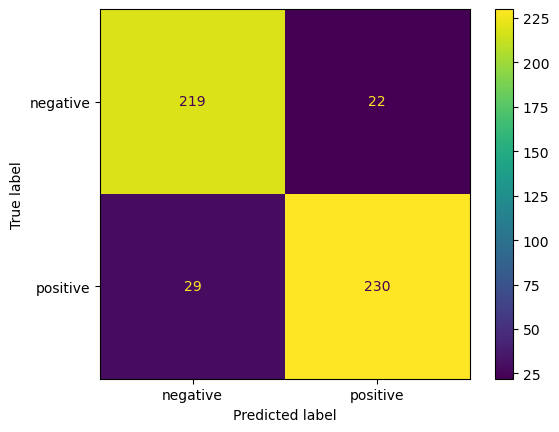

In [68]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["negative","positive"]
).plot()

plt.show()



## Save Model

In [69]:
model.save_pretrained("./sentiment_model")
tokenizer.save_pretrained("./sentiment_model")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('./sentiment_model/tokenizer_config.json', './sentiment_model/tokenizer.json')

In [70]:
# load 

model =  AutoModelForSequenceClassification.from_pretrained("./sentiment_model")
tokenizer =  AutoTokenizer.from_pretrained("./sentiment_model")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

In [86]:
# make the prediction function

import torch

def predict_sentiment(text):
    text = clean_data(text)

    inputs = tokenizer(
        text,
        padding="max_length",
        max_length = 512,
        truncation =True,
        return_tensors="pt"
    ).to(device)

    model.to(device)

    outputs = model(**inputs) # for classification , outputs - > logits

    # convert logits -> probabilites
    prob = torch.softmax(outputs.logits,dim=1)

    # find class with highest prob
    predicted_label = torch.argmax(outputs.logits,dim=1).item()

    confidence = prob[0][predicted_label].item()

    if predicted_label ==0:
        return "negative",confidence
    else:
        return "positive",confidence

    

In [88]:
sample_text = "i  loved the movie!!!! "

sentiment,confidence = predict_sentiment(sample_text)

print(sentiment)
print(f"confidence:{confidence:.2%}")

positive
confidence:99.64%
